# EpiAware — Synthetic Uncertainty Pipeline Validation

This notebook validates the EpiAware uncertainty evaluation pipeline
using synthetic ensemble logits.

It tests the shared corruption functions, uncertainty metrics,
calibration, error detection, selective prediction, and result exports.

**Note:** This notebook uses synthetic predictions. It does not
represent evaluation of the trained CIFAR-10 ResNet-18 ensemble.

In [1]:
import sys
from pathlib import Path

def find_repo_root():
    candidates = [
        Path.cwd(),
        *Path.cwd().parents,
        Path("/content/Epiaware"),
    ]

    for candidate in candidates:
        if (candidate / "src" / "epiaware").is_dir():
            return candidate.resolve()

    raise FileNotFoundError(
        "Could not locate the EpiAware repository. "
        "Make sure the repository is cloned or open the notebook "
        "from within the repository."
    )

REPO_PATH = find_repo_root()
SRC_PATH = REPO_PATH / "src"

if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

print("Repository:", REPO_PATH)
print("Source directory:", SRC_PATH)


Repository: /Users/rheamathur/epiaware
Source directory: /Users/rheamathur/epiaware/src


In [2]:
import epiaware.evaluation.pipeline as evaluation
from epiaware.data import corruptions

print("Pipeline imported:", evaluation.__file__)
print("Corruptions imported:", corruptions.__file__)

print("\nImport validation successful!")

Pipeline imported: /Users/rheamathur/epiaware/src/epiaware/evaluation/pipeline.py
Corruptions imported: /Users/rheamathur/epiaware/src/epiaware/data/corruptions.py

Import validation successful!


In [3]:
# ------------------------------------------------
# IMPORTS
# ------------------------------------------------

import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

print("All external libraries imported successfully.")


All external libraries imported successfully.


Device: cpu
gaussian_noise PASSED
gaussian_blur PASSED
rotation PASSED

Synthetic labels created: 1000
Total conditions: 16
Saved summary: /Users/rheamathur/epiaware/results/synthetic_validation/evaluation_summary.csv
Saved samples: /Users/rheamathur/epiaware/results/synthetic_validation/Synthetic_Validation_clean_run_7_samples.csv
Completed 1/16: clean None
Saved summary: /Users/rheamathur/epiaware/results/synthetic_validation/evaluation_summary.csv
Saved samples: /Users/rheamathur/epiaware/results/synthetic_validation/Synthetic_Validation_gaussian_noise_severity_1_run_7_samples.csv
Completed 2/16: gaussian_noise 1
Saved summary: /Users/rheamathur/epiaware/results/synthetic_validation/evaluation_summary.csv
Saved samples: /Users/rheamathur/epiaware/results/synthetic_validation/Synthetic_Validation_gaussian_noise_severity_2_run_7_samples.csv
Completed 3/16: gaussian_noise 2
Saved summary: /Users/rheamathur/epiaware/results/synthetic_validation/evaluation_summary.csv
Saved samples: /Use

,experiment_name,corruption_type,severity,number_of_samples,number_of_models,ensemble_accuracy,model_1_accuracy,model_2_accuracy,model_3_accuracy,model_1_entropy,...,ensemble_ece,entropy_auroc,entropy_auprc,entropy_aurc,variation_ratio_auroc,variation_ratio_auprc,variation_ratio_aurc,jsd_auroc,jsd_auprc,jsd_aurc
0,Synthetic Validation,clean,NaN,1000,3,0.106,0.083,0.097,0.093,1.925854,...,0.106485,0.479328,0.893879,0.900518,0.493130,0.892688,0.904525,0.489606,0.898716,0.904674
1,Synthetic Validation,gaussian_noise,1.0,1000,3,0.080,0.108,0.100,0.084,1.924016,...,0.135389,0.423641,0.908127,0.935165,0.520992,0.923140,0.915701,0.544130,0.932499,0.907401
2,Synthetic Validation,gaussian_noise,2.0,1000,3,0.093,0.100,0.093,0.083,1.923871,...,0.119178,0.476414,0.902145,0.910433,0.477665,0.903220,0.919644,0.469419,0.900497,0.920553
3,Synthetic Validation,gaussian_noise,3.0,1000,3,0.110,0.095,0.128,0.100,1.926562,...,0.103720,0.502421,0.893961,0.887988,0.458212,0.881821,0.909900,0.502022,0.900483,0.886812
4,Synthetic Validation,gaussian_noise,4.0,1000,3,0.109,0.120,0.092,0.107,1.927688,...,0.103056,0.461032,0.886283,0.899448,0.466917,0.884572,0.900022,0.534180,0.901857,0.878068
5,Synthetic Validation,gaussian_noise,5.0,1000,3,0.094,0.112,0.098,0.096,1.908175,...,0.123364,0.467557,0.903201,0.915616,0.523989,0.910154,0.893956,0.492027,0.907565,0.901543
6,Synthetic Validation,gaussian_blur,1.0,1000,3,0.089,0.090,0.098,0.088,1.929904,...,0.125825,0.509935,0.913464,0.907676,0.495196,0.910227,0.917926,0.491459,0.911687,0.912003
7,Synthetic Validation,gaussian_blur,2.0,1000,3,0.096,0.108,0.086,0.091,1.922202,...,0.117939,0.510474,0.901529,0.899288,0.501423,0.904252,0.902790,0.497742,0.903901,0.903660
8,Synthetic Validation,gaussian_blur,3.0,1000,3,0.107,0.119,0.100,0.106,1.928344,...,0.106248,0.455903,0.875230,0.899501,0.535191,0.899923,0.889423,0.528126,0.902183,0.890745
9,Synthetic Validation,gaussian_blur,4.0,1000,3,0.110,0.104,0.108,0.100,1.922059,...,0.103336,0.554433,0.904646,0.874061,0.514995,0.892963,0.882987,0.467038,0.884523,0.889632



SAMPLE RESULTS


,ground_truth,prediction,correct,error,ensemble_confidence,ensemble_entropy,variation_ratio,jsd,model_1_entropy,model_2_entropy,model_3_entropy
0,6,8,False,1,0.142969,2.230296,0.666667,0.206973,2.001165,2.064561,2.004243
1,3,4,False,1,0.230525,2.170483,0.333333,0.160017,1.889065,2.052310,2.090024
2,7,4,False,1,0.196822,2.226464,0.666667,0.160569,2.173467,1.918133,2.106087
3,4,8,False,1,0.236407,2.131154,0.666667,0.277163,1.585548,2.018543,1.957882
4,6,6,True,0,0.194586,2.107305,0.666667,0.136956,1.809831,2.029168,2.072047


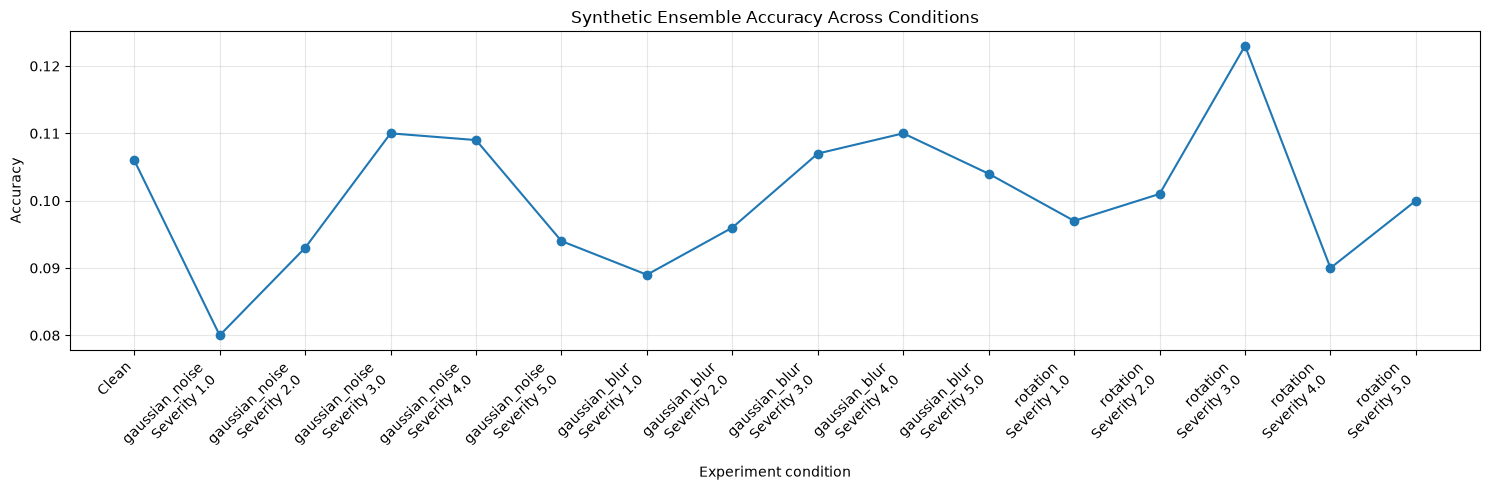

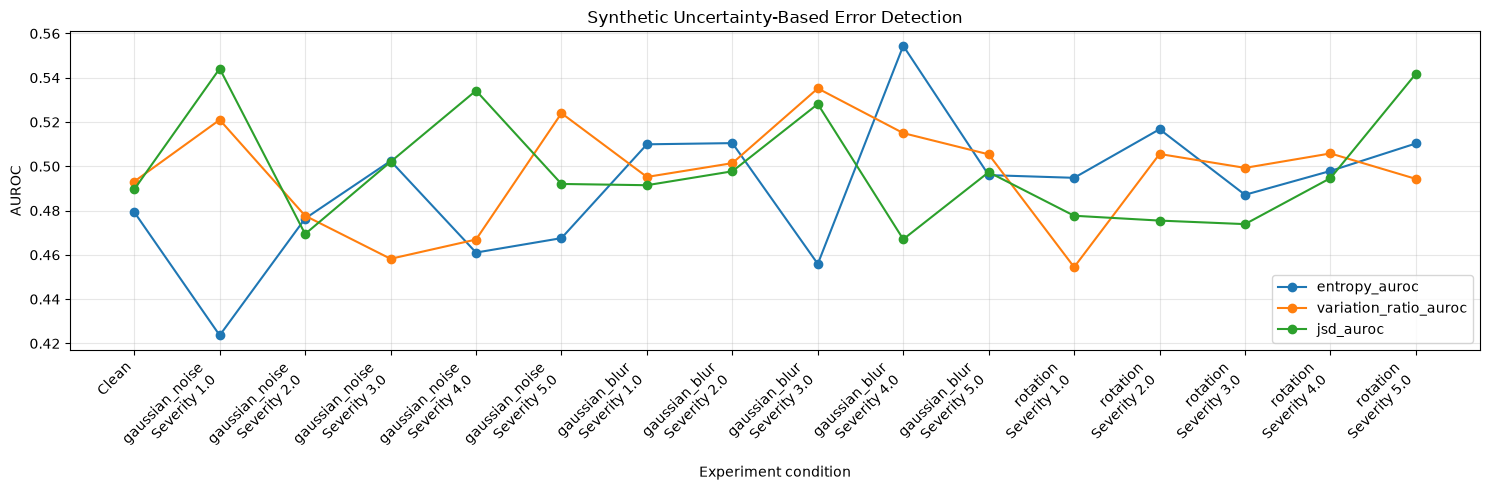

In [7]:
# ------------------------------------------------
# 2. REPRODUCIBILITY
# ------------------------------------------------

RANDOM_SEED = 42
ENSEMBLE_SIZE = 3
NUM_CLASSES = 10
NUM_SAMPLES = 1000

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

OUTPUT_DIR = REPO_PATH / "results" / "synthetic_validation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", device)

# ------------------------------------------------
# 3. SHARED CORRUPTION FUNCTIONS
# ------------------------------------------------

CORRUPTION_FUNCTIONS = {
    "gaussian_noise": corruptions.gaussian_noise,
    "gaussian_blur": corruptions.gaussian_blur,
    "rotation": corruptions.rotation
}

def apply_corruption(images, corruption_type, severity):

    if corruption_type not in CORRUPTION_FUNCTIONS:
        raise ValueError("Unknown corruption type.")

    if not 1 <= severity <= 5:
        raise ValueError("Severity must be between 1 and 5.")

    corrupted_images = []

    for image_index, image in enumerate(images):

        image_array = (
            image.detach()
            .cpu()
            .permute(1, 2, 0)
            .numpy()
        )

        image_array = np.clip(
            np.rint(image_array * 255),
            0,
            255
        ).astype(np.uint8)

        if corruption_type == "gaussian_noise":
            corrupted_image = corruptions.gaussian_noise(
                image_array,
                severity,
                seed=RANDOM_SEED + image_index
            )
        else:
            corrupted_image = CORRUPTION_FUNCTIONS[
                corruption_type
            ](image_array, severity)

        corrupted_tensor = torch.from_numpy(
            corrupted_image.copy()
        )

        corrupted_tensor = (
            corrupted_tensor.permute(2, 0, 1).float() / 255.0
        )

        corrupted_images.append(corrupted_tensor)

    return torch.stack(corrupted_images)

# ------------------------------------------------
# 4. TEST CORRUPTION IMPLEMENTATION
# ------------------------------------------------

dummy_images = torch.rand(8, 3, 32, 32)

for corruption_type in CORRUPTION_FUNCTIONS:

    corrupted_images = apply_corruption(
        dummy_images,
        corruption_type,
        severity=3
    )

    assert corrupted_images.shape == dummy_images.shape
    assert torch.isfinite(corrupted_images).all()
    assert torch.all(corrupted_images >= 0)
    assert torch.all(corrupted_images <= 1)

    print(corruption_type, "PASSED")

# ------------------------------------------------
# 7. CREATE SYNTHETIC TEST LABELS
# ------------------------------------------------

ground_truth = np.random.randint(
    0,
    NUM_CLASSES,
    size=NUM_SAMPLES
)

print("\nSynthetic labels created:", len(ground_truth))

# ------------------------------------------------
# 8. EXPERIMENT CONFIGURATIONS
# ------------------------------------------------

experiment_configs = [
    {
        "corruption": "clean",
        "severity": None
    }
]

for corruption_type in CORRUPTION_FUNCTIONS:

    for severity in range(1, 6):

        experiment_configs.append({
            "corruption": corruption_type,
            "severity": severity
        })

print("Total conditions:", len(experiment_configs))


# ------------------------------------------------
# 9. RUN SYNTHETIC EVALUATION
# ------------------------------------------------

all_summaries = []
all_sample_results = []

for condition_index, config in enumerate(experiment_configs):

    corruption_type = config["corruption"]
    severity = config["severity"]

    # Synthetic logits are used only to validate
    # the evaluation pipeline.

    synthetic_logits = np.random.randn(
        ENSEMBLE_SIZE,
        NUM_SAMPLES,
        NUM_CLASSES
    )

    # Shared evaluation pipeline handles:
    # - Stable softmax conversion
    # - Individual member entropy
    # - Ensemble entropy
    # - Error detection
    # - Calibration
    # - Selective prediction

    summary, sample_results = evaluation.evaluate_ensemble_logits(
        synthetic_logits,
        ground_truth,
        experiment_name="Synthetic Validation",
        corruption_type=corruption_type,
        severity=severity
    )

    all_summaries.append(summary)
    all_sample_results.append(sample_results)

    
    summary_path, samples_path = evaluation.save_evaluation_results(
        summary,
        sample_results,
        output_directory=OUTPUT_DIR
    )

    print("Saved summary:", summary_path)
    print("Saved samples:", samples_path)


    print(
        f"Completed {condition_index + 1}/16:",
        corruption_type,
        severity
    )

# ------------------------------------------------
# 10. COMBINE ALL EXPERIMENT RESULTS
# ------------------------------------------------

summary_df = pd.DataFrame(all_summaries)

sample_df = pd.concat(
    all_sample_results,
    ignore_index=True
)

print("\nSUMMARY RESULTS")
display(summary_df)

print("\nSAMPLE RESULTS")
display(sample_df.head())

# ------------------------------------------------
# VISUALIZATION 1: ENSEMBLE ACCURACY
# ------------------------------------------------

condition_labels = [
    f"{row['corruption_type']}\n"
    f"Severity {row['severity']}"
    if pd.notna(row["severity"])
    else "Clean"
    for _, row in summary_df.iterrows()
]

plt.figure(figsize=(15, 5))

plt.plot(
    condition_labels,
    summary_df["ensemble_accuracy"],
    marker="o"
)

plt.xlabel("Experiment condition")
plt.ylabel("Accuracy")
plt.title("Synthetic Ensemble Accuracy Across Conditions")
plt.xticks(rotation=45, ha="right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# VISUALIZATION 2: ERROR DETECTION AUROC
# ------------------------------------------------

auroc_columns = [
    "entropy_auroc",
    "variation_ratio_auroc",
    "jsd_auroc"
]

plt.figure(figsize=(15, 5))

for column in auroc_columns:
    plt.plot(
        condition_labels,
        summary_df[column],
        marker="o",
        label=column
    )

plt.xlabel("Experiment condition")
plt.ylabel("AUROC")
plt.title("Synthetic Uncertainty-Based Error Detection")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:
# ------------------------------------------------
# MISSING-VALUE ANALYSIS
# ------------------------------------------------

if "summary_df" not in globals():
    raise RuntimeError(
        "summary_df is unavailable. "
        "Run the synthetic evaluation cell first."
    )

numeric_columns = summary_df.select_dtypes(
    include=[np.number]
).columns.tolist()

# Severity is experiment metadata, not an evaluation metric.
metric_columns = [
    column for column in numeric_columns
    if column != "severity"
]

missing_values = summary_df[metric_columns].isna().sum()

print("Columns containing missing values:")

if missing_values.any():
    print(missing_values[missing_values > 0])
else:
    print("No missing values found in numeric metrics.")

print("\nAffected experiment conditions:")

for column in metric_columns:
    if summary_df[column].isna().any():
        print(f"\n{column}")

        display(
            summary_df.loc[
                summary_df[column].isna(),
                ["corruption_type", "severity"]
            ]
        )


Columns containing missing values:
No missing values found in numeric metrics.

Affected experiment conditions:


In [9]:
# ------------------------------------------------
# FINAL PIPELINE VALIDATION
# ------------------------------------------------

# 1. Verify experiment conditions

assert len(experiment_configs) == 16
assert len(summary_df) == 16

assert len(sample_df) == 16 * NUM_SAMPLES

# 2. Verify individual member entropy

for index in range(1, ENSEMBLE_SIZE + 1):
    assert f"model_{index}_entropy" in sample_df.columns

# 3. Verify ensemble uncertainty outputs

required_sample_columns = [
    "ensemble_entropy",
    "variation_ratio",
    "jsd",
    "prediction",
    "ground_truth",
    "error"
]

for column in required_sample_columns:
    assert column in sample_df.columns, (
        f"Missing sample-level column: {column}"
    )

# 4. Verify summary metrics

required_summary_columns = [
    "ensemble_accuracy",
    "ensemble_ece",
    "entropy_auroc",
    "entropy_auprc",
    "entropy_aurc"
]

for column in required_summary_columns:
    assert column in summary_df.columns, (
        f"Missing summary column: {column}"
    )

# 5. Verify finite values in essential metrics

essential_metrics = [
    "ensemble_accuracy",
    "ensemble_ece",
    "entropy_aurc"
]

for column in essential_metrics:
    assert np.isfinite(summary_df[column]).all(), (
        f"Invalid values found in {column}"
    )

# 6. Verify uncertainty outputs are finite

uncertainty_columns = [
    "ensemble_entropy",
    "variation_ratio",
    "jsd"
]

for column in uncertainty_columns:
    assert np.isfinite(sample_df[column]).all(), (
        f"Invalid values found in {column}"
    )

# 7. Verify prediction error labels

expected_errors = (
    sample_df["prediction"].to_numpy()
    != sample_df["ground_truth"].to_numpy()
).astype(int)

assert np.array_equal(
    sample_df["error"].to_numpy(),
    expected_errors
)

print("All structural and numerical checks passed.")

print("\n" + "=" * 55)
print("EPIAWARE SYNTHETIC PIPELINE VALIDATION PASSED")
print("=" * 55)

print("Experiment conditions: 16")
print("Sample-level records:", len(sample_df))
print("Individual member entropy: PASSED")
print("Ensemble uncertainty: PASSED")
print("Error labels: PASSED")
print("Calibration output: PASSED")
print("Selective prediction output: PASSED")

print("\nIMPORTANT:")
print("These results use synthetic predictions.")
print("Trained CIFAR-10 ensemble evaluation is still pending.")


All structural and numerical checks passed.

EPIAWARE SYNTHETIC PIPELINE VALIDATION PASSED
Experiment conditions: 16
Sample-level records: 16000
Individual member entropy: PASSED
Ensemble uncertainty: PASSED
Error labels: PASSED
Calibration output: PASSED
Selective prediction output: PASSED

IMPORTANT:
These results use synthetic predictions.
Trained CIFAR-10 ensemble evaluation is still pending.
